# Investigating river-level data across Scotland


**Emma Deyell, Gabriela Krawczyk & Saba Sitter**

# Setup

In [1]:
# Data handling and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Clustering and evaluation
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Supervised-learning 
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder

plt.rcParams.update({
    "figure.figsize": (7, 3),
    "font.size": 10,
    "figure.dpi": 150
})

In [2]:
# Load data  
df_avg = pd.read_csv("csv_files/avg_river_levels.csv")
df_min = pd.read_csv("csv_files/min_river_levels.csv")
df_max = pd.read_csv("csv_files/max_river_levels.csv")
df_locs = pd.read_csv("csv_files/monitoring_locations.csv")

# Introduction

This report investigates river water levels in Scotland using observations from 392 river-level monitoring stations obtained from River Levels UK [1]. Three datasets contain daily minimum, mean and maximum water levels, while a fourth provides station locations. Coverage varies by station and date. The report tries to address two questions: (i) whether stations can be grouped according to their observed water-level behaviour and (ii) whether daily water levels can be predicted for September–November 2026, based on previous water-level measurements, using linear regression.

We first assess the quality and completeness of the datasets, removing unreliable observations and applying appropriate preprocessing to ensure consistency across stations and dates. We then engineer additional features from the daily minimum, average and maximum water levels to capture patterns in water-level variability and temporal behaviour. These features provide a basis for investigating differences between monitoring stations and may also inform the regression analysis(CHANGE THIS ONCE REGRESSION IS DONE - either to also inform the regrsssion analysis (no 'may inform') if they do or just delete this sentence? I said may as we haven't done it yet).

To address the first question, we examine correlations between the engineered features and select a subset that avoids unnecessary redundancy. We then compare several clustering algorithms and hierarchical linkage methods before selecting Ward hierarchical clustering with four clusters. The resulting groups distinguish three broad patterns of river-level behaviour and a small group of eight stations with unusually large within-day fluctuations. The three major clusters exhibit an apparent east–west geographical association, with relatively stable stations more common in eastern Scotland and less persistent stations more common further west, although their geographical distributions overlap considerably.


The second question was investigated using supervised machine learning techniques, with the modelling approach and evaluation methods determined by the selected prediction task. WRITE MORE ABOUT QUESTION 2

# Exploratory Data Analysis and Feature Engineering

## Exploratory Data Analysis


Invalid observations excluded: 79
Extreme outliers excluded (10 × IQR): 370
Dates excluded (>50% missing): 1094
Stations excluded (>10% missing): 63
Final dataset: 314 stations, 3293 dates


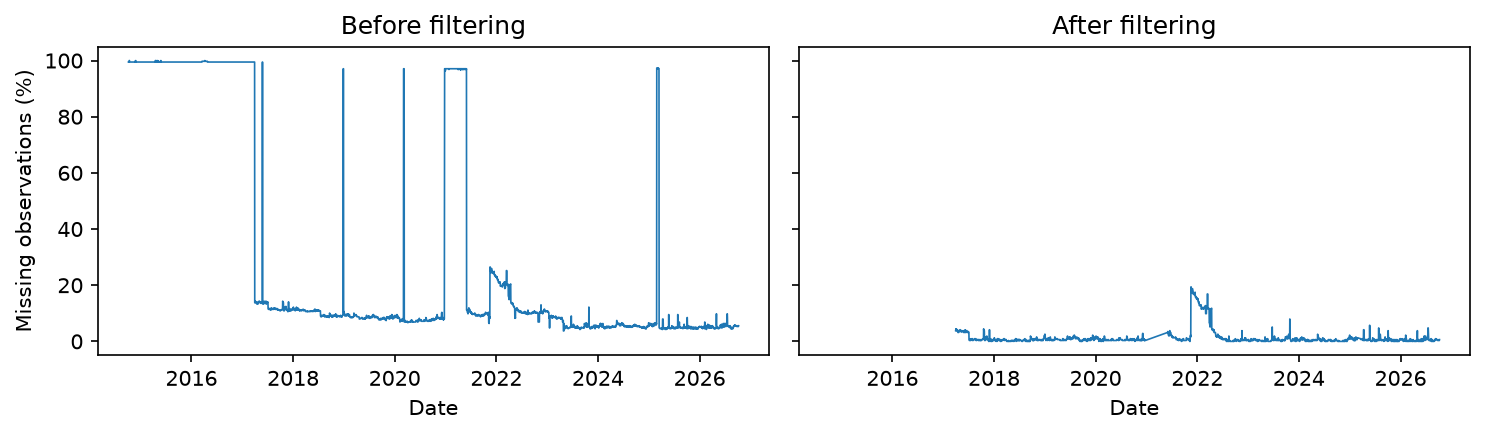

In [3]:
# Identify stations outside Scotland
stations_to_remove = df_locs.loc[
    df_locs["Station_Name"].str.strip().str.lower().isin(
        ["portrush", "bangor", "port erin"]),
    "Observation_ID"
].tolist()

# Identify stations with additional tidal observations
tidal_ids = df_locs.loc[
    df_locs["Observation_ID"].str.contains("tidal-level", case=False, na=False),
    "Observation_ID"
].tolist()

# Record those stations with separately labelled tidal observations
df_locs["Has_Tidal_Observation"] = (
    df_locs.groupby(["County", "Station_Name"])["Observation_ID"]
    .transform(lambda s: s.str.contains("tidal-level", case=False, na=False).any())
    .astype(int)
)

stations_to_remove += tidal_ids


def prepare_data(df):
    ''' Removes values we deem erroneous, as well as stations outside of Scotland and the tidal observations'''
    vals = df.iloc[:, 3:].copy()
    vals.columns = pd.to_datetime(vals.columns, dayfirst=True)
    vals.index = df["Observation_ID"]
    vals = vals.T.sort_index().asfreq("D")

    # Replace missing-value codes
    vals = vals.replace([999999.999, -999999.999, -99], np.nan)

    # Remove unwanted observation series
    vals = vals.drop(columns=stations_to_remove, errors="ignore")

    return vals


vals1 = prepare_data(df_avg)
vals2 = prepare_data(df_min)
vals3 = prepare_data(df_max)

# Check that all three datasets have identical stations and dates
assert vals1.index.equals(vals2.index) and vals1.index.equals(vals3.index)
assert vals1.columns.equals(vals2.columns) and vals1.columns.equals(vals3.columns)

# Identify invalid station-days across all three measurements
invalid = (
    (vals1.abs() > 100) |
    (vals2.abs() > 100) |
    (vals3.abs() > 100) |
    (vals2 > vals1) |
    (vals1 > vals3)
)

# Remove invalid observations before calculating outlier thresholds
vals1 = vals1.mask(invalid)
vals2 = vals2.mask(invalid)
vals3 = vals3.mask(invalid)

# Identify extreme outliers using station-specific IQR thresholds
Q1 = vals1.quantile(0.25)
Q3 = vals1.quantile(0.75)
IQR = Q3 - Q1

outliers = (
    vals1.lt(Q1 - 10 * IQR, axis=1) |
    vals1.gt(Q3 + 10 * IQR, axis=1)
)

# Remove outlier station-days consistently from all datasets
vals1 = vals1.mask(outliers)
vals2 = vals2.mask(outliers)
vals3 = vals3.mask(outliers)

# Filter dates with more than 50% missing observations
good_dates = vals1.index[vals1.isna().mean(axis=1) <= 0.5]

# Filter stations with more than 10% missing observations
good_stations = vals1.loc[good_dates].columns[
    vals1.loc[good_dates].isna().mean(axis=0) <= 0.1
]

filtered_avg = vals1.loc[good_dates, good_stations].copy()
filtered_min = vals2.loc[good_dates, good_stations].copy()
filtered_max = vals3.loc[good_dates, good_stations].copy()

# Retain data for the remaining stations
df_locs_filtered = df_locs[
    df_locs["Observation_ID"].isin(good_stations)
].copy()

# Summarise data cleaning
print(f"Invalid observations excluded: {int(invalid.sum().sum())}")
print(f"Extreme outliers excluded (10 × IQR): {int(outliers.sum().sum())}")

print(f"Dates excluded (>50% missing): {len(vals1) - len(good_dates)}")
print(f"Stations excluded (>10% missing): {vals1.shape[1] - len(good_stations)}")

print(f"Final dataset: {filtered_avg.shape[1]} stations, {len(filtered_avg)} dates")


# Percentage of missing observations on each date
missing_before = vals1.isna().mean(axis=1) * 100
missing_after = filtered_avg.isna().mean(axis=1) * 100

fig, ax = plt.subplots(1, 2, figsize=(10, 3), sharex=True, sharey=True)

for a, data, title in zip(
    ax,
    [missing_before, missing_after],
    ["Before filtering", "After filtering"]
):
    a.plot(data.index, data, linewidth=0.8)
    a.set(xlabel="Date", title=title)

ax[0].set_ylabel("Missing observations (%)")
plt.tight_layout()
plt.show()

*Figure 1: Percentage of missing data over time before and after filtering.*

In [4]:
print(f"Missing before: {vals1.isna().values.mean():.2%}")
print(f"Missing after: {filtered_avg.isna().values.mean():.2%}")

Missing before: 31.08%
Missing after: 1.30%


### Data cleaning and preprocessing

River Levels UK states that its historical downloads contain raw, unchecked observations and may include errors [RIVER LEVELS UK], therefore the datasets were examined for missing, inconsistent and potentially erroneous observations before modelling. 

We identified three stations located outside Scotland (Portrush, Bangor and Port Erin), which were excluded from the analysis. Observations labelled as tidal-level were also removed to focus the clustering on river-level behaviour. Tidal water levels are measured relative to a different reference datum, making their fluctuations less directly comparable with those of inland rivers. Including these observations could therefore skew the clustering. We have however retained information on stations with tidal observations in the location metadata, for later interpretation. We note that these are not necessarily the only rivers affected by tides, but rather those for which our data source provides separate tidal observation series.


The data were converted to a common daily time index, and the placeholder values `999999.999`, `-999999.999` and `-99` were treated as missing. We verified that the minimum, average and maximum datasets contained identical stations and dates. Measurements were then excluded where any absolute reading exceeded 100 m or where the expected relationship between daily measurements was violated (minimum ≤ average ≤ maximum). The 100 m threshold was chosen as a deliberately generous safeguard against implausible values.

Extreme outliers were identified using the distribution of daily average water levels at each station. We calculated the interquartile range (IQR), defined as the difference between the 75th and 25th percentiles, and excluded observations more than 10 IQRs below the 25th percentile or above the 75th percentile. This approach accounts for differences in typical water levels and variability between stations, while the generous threshold aims to remove only exceptionally large deviations and preserve most natural fluctuations. Although some genuine extreme high- or low-water events may have been excluded, we consider this a reasonable compromise between data quality and retaining meaningful variation. This decision was further supported by comparing several unusually high observations against the highest recorded levels reported by River Levels UK, which revealed discrepancies of several metres above the reported historical maxima. 

Whenever an observation was excluded, its corresponding minimum, average and maximum measurements were all treated as missing to maintain consistency.

Finally, dates with more than 50% missing average-level observations were removed, followed by stations with more than 10% missing observations across the retained dates. These thresholds balance data coverage against the need for sufficiently complete time series. 

This selection may favour stations with longer, more reliable records and may underrepresent locations with sparse observations. 

Figure 1 illustrates the distribution of missing observations before and after completeness filtering.

## Feature Engineering 

In [9]:
# Each row represents a station; columns are daily observations.
avg = filtered_avg.T.copy()
min_level = filtered_min.T.copy()
max_level = filtered_max.T.copy()

df_features = df_locs_filtered.set_index("Observation_ID").loc[avg.index].copy()

daily_range = max_level - min_level
daily_change = filtered_avg.asfreq("D").diff().T  # Only consecutive calendar days

# Within-day variation and variation over the observation period
df_features["Median_Daily_Range"] = daily_range.median(axis=1)
df_features["IQR_Level"] = avg.quantile(0.75, axis=1) - avg.quantile(0.25, axis=1)
df_features["Mean_Absolute_Daily_Change"] = daily_change.abs().mean(axis=1)

# Extreme rises relative to each station's typical positive daily changes
positive_change = daily_change.where(daily_change > 0)
rise_threshold = positive_change.stack().quantile(0.90)
df_features["Percent_Extreme_Rises"] = (
    daily_change.gt(rise_threshold).sum(axis=1)
    / daily_change.notna().sum(axis=1) * 100
)

# Compare typical daily rises and falls
mean_rise = positive_change.mean(axis=1)
mean_fall = -daily_change.where(daily_change < 0).mean(axis=1)
df_features["Rise_Fall_Asymmetry"] = mean_rise / mean_fall.replace(0, np.nan)

# Seasonal variation: difference between highest and lowest monthly median levels
monthly_medians = filtered_avg.groupby(filtered_avg.index.month).median().T
df_features["Seasonal_Amplitude"] = monthly_medians.max(axis=1) - monthly_medians.min(axis=1)

# Day-to-day persistence and variability of the within-day range
df_features["Daily_level_persistence"] = avg.apply(
    lambda row: row.autocorr(lag=1), axis=1
)

df_features["Range_Variability"] = (
    daily_range.quantile(0.75, axis=1) -
    daily_range.quantile(0.25, axis=1)
)

feature_cols = [
    "Median_Daily_Range", "IQR_Level", "Mean_Absolute_Daily_Change",
    "Percent_Extreme_Rises", "Rise_Fall_Asymmetry", "Seasonal_Amplitude",
    "Daily_level_persistence", "Range_Variability"
]
feature_cols2 = [
    "Median_Daily_Range", "IQR_Level", "Mean_Absolute_Daily_Change",
    "Rise_Fall_Asymmetry", "Daily_level_persistence"
]

df_features = df_features.reset_index()
assert df_features[feature_cols].notna().all().all(), "Check missing engineered features"

The daily observations were used to create station-level features (Table 1). These measures describe different aspects of river-level behaviour rather than absolute water height, which depends on the local gauge reference level. 

| Feature | Description |
|---|---|
| Median daily range | Typical difference between daily maximum and minimum water levels |
| IQR of average level | Spread of the middle 50% of daily average levels |
| Mean absolute daily change | Typical magnitude of change in average level between consecutive days |
| Percentage of extreme rises | Percentage of valid daily changes exceeding the station's 90th percentile of positive changes |
| Rise–fall asymmetry | Mean positive daily change divided by the magnitude of the mean negative daily change |
| Seasonal amplitude | Difference between the highest and lowest calendar-month median average levels |
| Daily level persistence | Measures how strongly a station's water level on one day is related to its water level on the previous day |
| Range variability | Standard deviation of daily maximum-minus-minimum ranges |
| Std_Level | Standard deviation of average river level |


*Table 1: Features created from river-level data.*

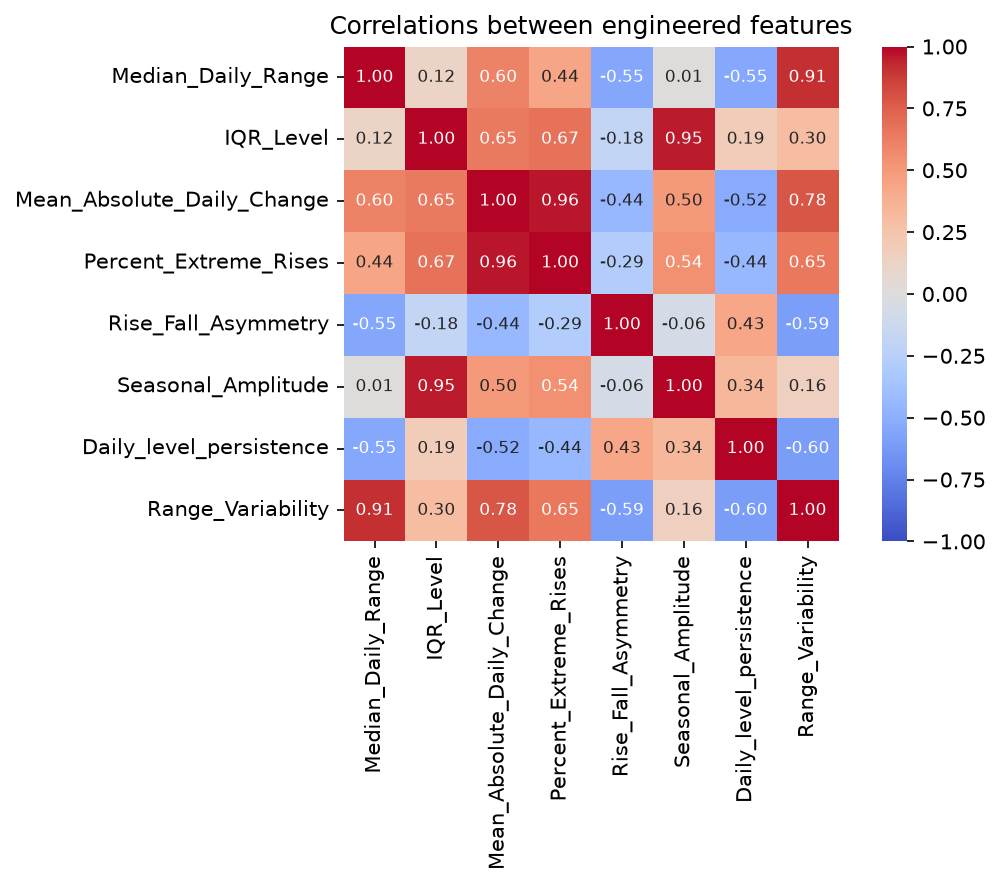

In [15]:
# Compare engineered features before choosing the final clustering inputs
df_visualise = df_features[feature_cols].copy()

plt.figure(figsize=(8, 6))
sns.heatmap(df_visualise.corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True,
            annot_kws={"size": 8})
plt.title("Correlations between engineered features")
plt.tight_layout()
plt.show()

*Figure 2: Correlation matrix of the engineered river-level features.*

The features in Table 1 were designed to distinguish stations with different types of water-level behaviour. Median daily range captures typical within-day fluctuations, while the IQR of average levels measures variability across the observation period. Mean absolute daily change describes the magnitude of day-to-day movements, rise–fall asymmetry distinguishes the typical sizes of rises and falls, and daily level persistence measures how strongly a day's level resembles the preceding day's level. Daily changes were calculated only between consecutive calendar days, so gaps were not mistaken for single-day changes.

The remaining three features were initially considered to capture additional aspects of station behaviour. However the correlation matrix (Figure 2) revealed strong relationships between several engineered features. In particular, percentage of extreme rises was highly correlated with mean absolute daily change (0.96), seasonal amplitude with IQR of average level (0.95), and variability of daily ranges with median daily range (0.91). This suggested that including all eight features could give overlapping aspects of river-level behaviour excessive influence in distance-based clustering.

After further investigating these relationships on a pairwise scatterplot of the features, we considered a reduced set of five features, excluding percentage of extreme rises, seasonal amplitude and variability of daily ranges. Mean absolute daily change was retained as a more general measure of day-to-day fluctuations, capturing both rises and falls rather than only unusually large rises. Similarly, IQR of average level was preferred as a measure of overall water-level variability that does not rely on seasonal patterns, while median daily range provides a straightforward measure of typical within-day fluctuations.

We explored clustering using both the original eight features and the reduced set of five to assess how feature selection influenced the results. The two approaches produced broadly similar patterns, although some differences in cluster assignments and group sizes were observed. We ultimately preferred the five-feature approach, as it reduced redundancy and allowed the clusters to be interpreted in terms of distinct aspects of river-level behaviour, without giving excessive weight to highly correlated measures. The five selected features: *median daily range, IQR of average level, mean absolute daily change, rise–fall asymmetry and daily level persistence*, were therefore used for the final clustering analysis. They capture within-day variability, longer-term variability, day-to-day changes, directional asymmetry and temporal dependence. All eight features remain available for other analyses. (DELETE THIS - all eight remain - IF WE DON'T USE THEM FOR ANY ANALYSIS IN REGRESSION).

## Clustering

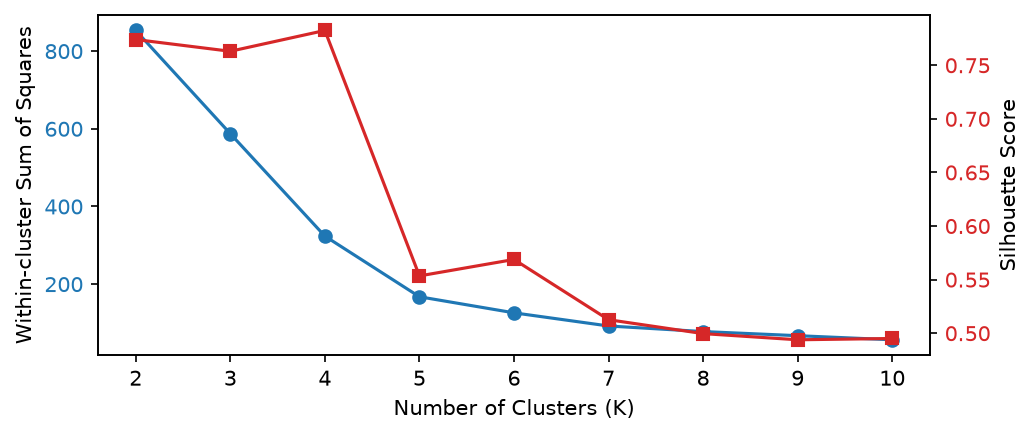

In [45]:
feature_cols = df_visualise.columns
df_scaled = StandardScaler().fit_transform(df_visualise) #Standardise 

#Silhouette plot
K_range = range(2, 11)
inertias, silhouette_scores = [], []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(df_scaled, labels))

fig, ax1 = plt.subplots()
ax1.plot(K_range, inertias, "o-", color="tab:blue")
ax1.set(xlabel="Number of Clusters (K)",
        ylabel="Within-cluster Sum of Squares")

ax2 = ax1.twinx()
ax2.plot(K_range, silhouette_scores, "s-", color="tab:red")
ax2.set_ylabel("Silhouette Score")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax2.tick_params(axis="y", labelcolor="tab:red")

plt.tight_layout()
plt.show()



*Figure 3: Within-cluster variation and silhouette coefficients for different values of K.*

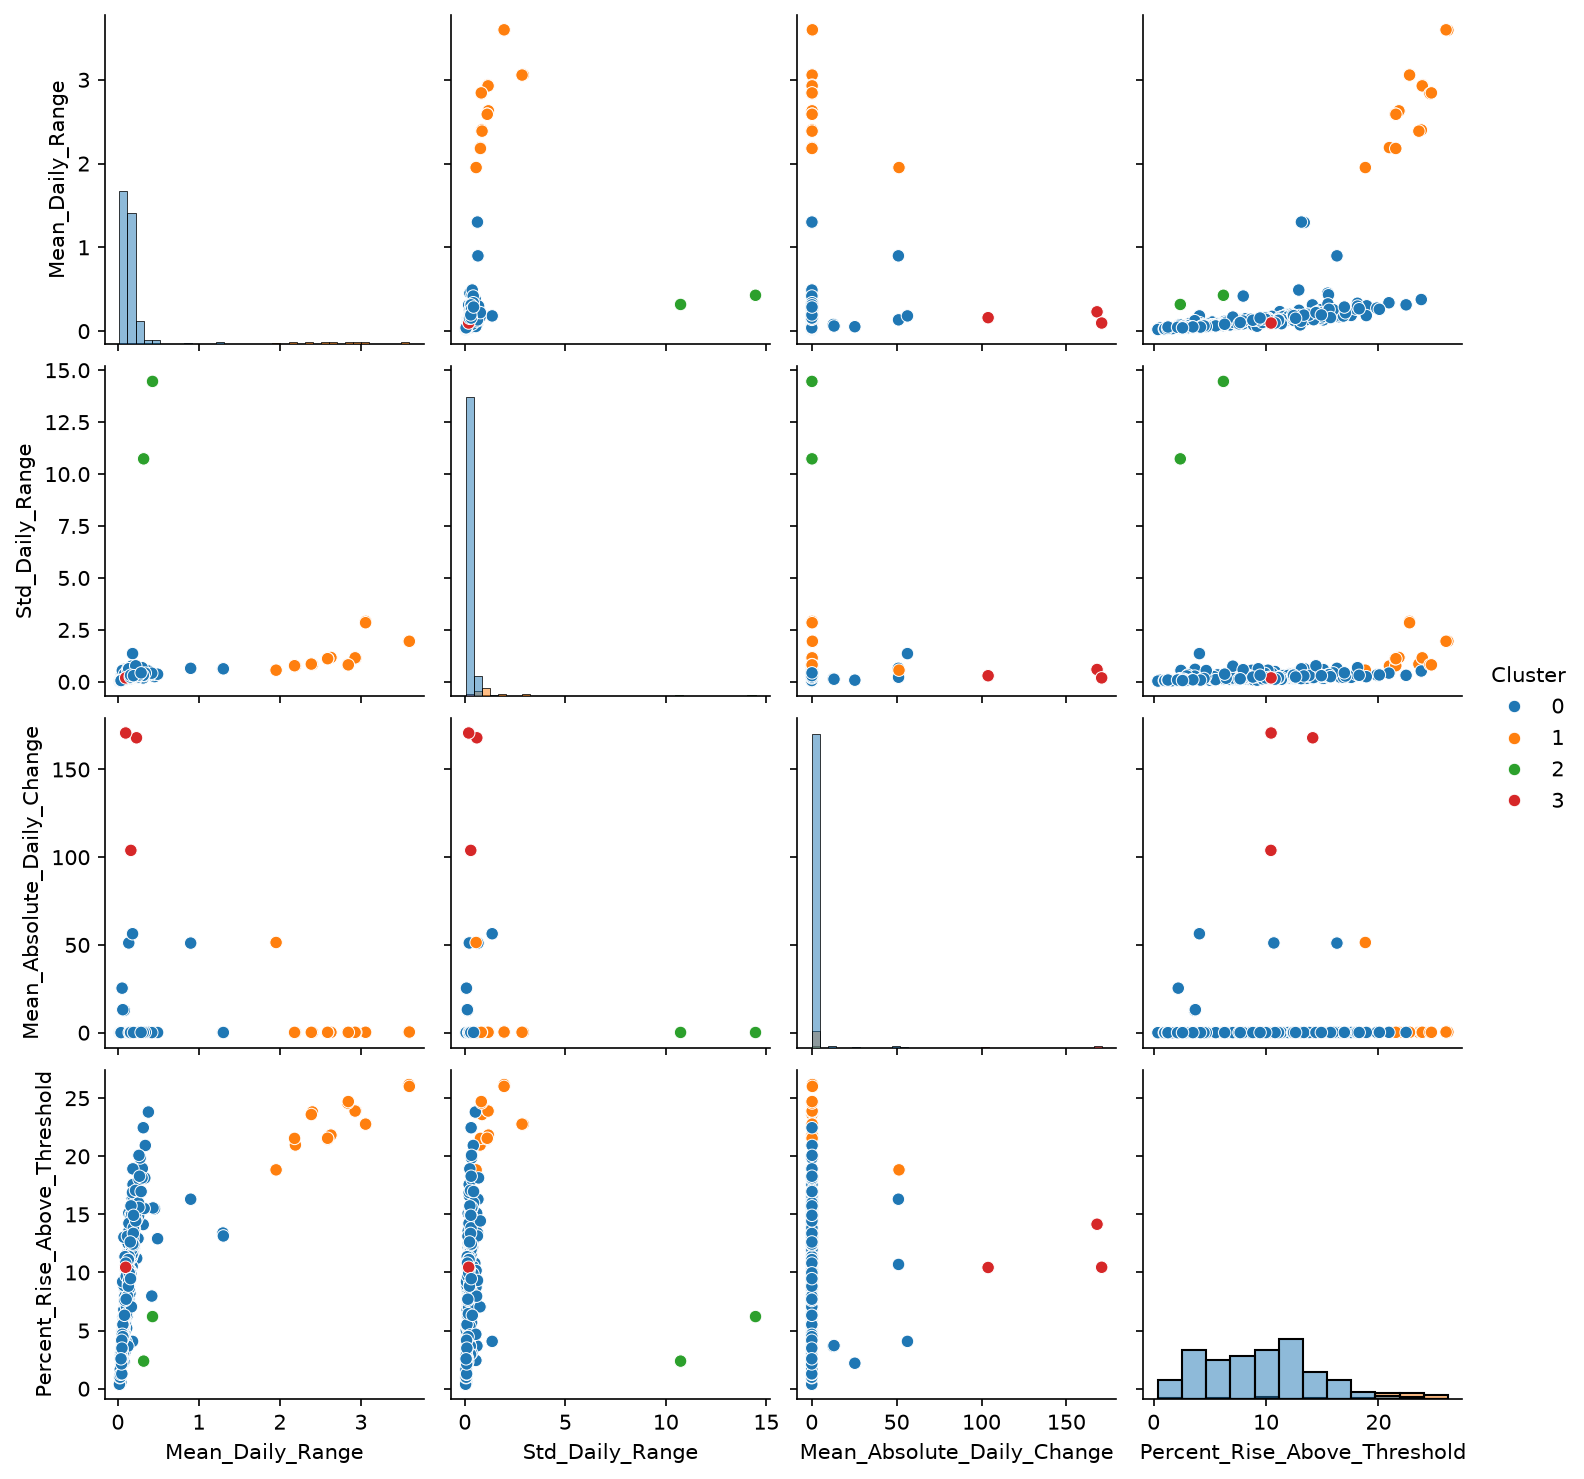

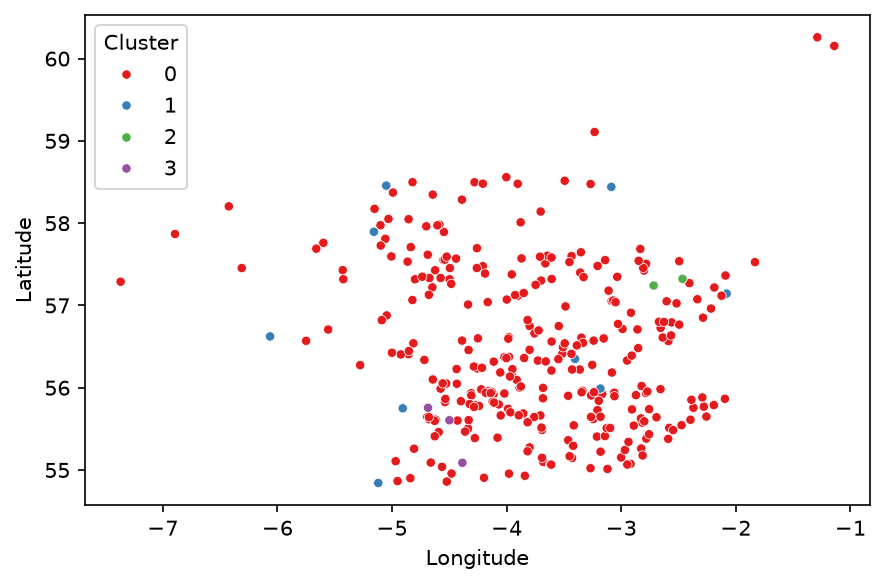

In [46]:
#Finding and assigning the clusters
K_final = 4  # Replace with final choice
kmeans = KMeans(n_clusters=K_final, random_state=42, n_init=10)
df_features["Cluster"] = kmeans.fit_predict(df_scaled)

#Visualise using pairplots 
df_visualise = df_features.drop(columns = ['Station_Name', 'Latitude', 'Longitude'])
sns.pairplot(df_visualise, hue = "Cluster", palette='tab10', diag_kind='hist')


#make this subplots with the geographical distribution
plt.figure(figsize = (6,4))
sns.scatterplot(data=df_features, x="Longitude", y="Latitude",
                hue="Cluster", palette="Set1", s=20)
plt.tight_layout()
plt.show()

*Figure 4: Pairplots demonstrating clustering relationships.*
*Figure 5: Visualisation of clusters and geographical distribution.*

In [47]:
cluster_summary = df_features.groupby("Cluster")[feature_cols].mean()
cluster_summary["Number of Stations"] = df_features.groupby("Cluster").size()

display(cluster_summary.T.round(3))

Cluster,0,1,2,3
Mean_Daily_Range,0.142,2.729,0.373,0.163
Std_Daily_Range,0.243,1.295,12.597,0.362
Mean_Absolute_Daily_Change,0.769,3.240,0.124,147.575
Percent_Rise_Above_Threshold,9.252,22.957,4.290,11.677
Number of Stations,301.000,17.000,2.000,3.000


*Table 3: Cluster characteristics.*


The features selected in the previous section were used as the basis for clustering the river monitoring stations according to similarities in their water-level behaviour. Due to differences in the scale and magnitude of the explanatory variables, standardisation was performed prior to clustering, such that each variable had a mean of zero and a standard deviation of one. This prevented variables with larger numerical values from disproportionately influencing the clustering results.

K-Means clustering was initially investigated due to its simplicity, computational efficiency and interpretability. The algorithm assigns observations to clusters by minimising the within-cluster sum of squared distances from their respective cluster centres.Hierarchical clustering was also considered as an alternative approach, as it does not require the number of clusters to be specified prior to constructing the cluster hierarchy. This provided an alternative means of investigating the underlying relationships between monitoring stations.

To investigate the optimal number of clusters for K-Means, the within-cluster variation and silhouette coefficients were calculated for different values of K. The within-cluster variation decreases as the number of clusters increases. However, increasing the number of clusters does not necessarily produce a more meaningful clustering solution. The elbow method was therefore used to identify a point beyond which additional clusters provided relatively little improvement. The silhouette coefficient was also used to assess how closely observations were associated with their assigned clusters relative to neighbouring clusters. Higher silhouette coefficients indicate greater cluster cohesion and separation.

As shown in Figure 4, the rate of decrease in within-cluster variation became less substantial beyond approximately K = 3. The highest silhouette coefficient was obtained for K = 4. However, the distribution of stations across clusters and the interpretability of the resulting groups were also considered when selecting the final clustering solution, and so K = 3 was chosen as it was also above the 90% threshold of the explained variance ratio.

To further investigate the characteristics of the resulting clusters, the average values of the explanatory variables within each cluster were calculated. The main distinguishing characteristics between the clusters were [FEATURES]. Monitoring stations within Cluster 1 were characterised by [XX], whilst those within Cluster 2 exhibited [XX].

The geographical distribution of the resulting clusters was investigated to determine whether similarities in water-level behaviour were associated with geographical location. As shown in Figure 5, [DISCUSS GEOGRAPHICAL PATTERNS AND POTENTIAL EXPLANATIONS].

## Data Preparation for Supervised Learning

To evaluate the predictive performance of the supervised learning model, the dataset was divided into training and testing sets. Due to the time-dependent nature of river-level observations, the data were split chronologically rather than randomly. This prevented future observations from being used to predict historical water levels and make the forecasting more realistic.

The training dataset consisted of observations between 31/03/2017 and 31/08/2026. The forecasting period extended from 01/09/2026 to 30/11/2026, however, as recorded observations were only available until 08/10/2026, model performance could only be evaluated until then. 

Further feature engineering was undertaken to construct explanatory variables relevant to water-level prediction.

[EDIT TO ADD FEATURES AND JUSTIFICAITON ]

A sklearn pipeline was used to incorporate the necessary preprocessing steps into the model-fitting process, ensuring that any preprocessing requiring fitted parameters was based solely on the training data. The implementation of this pipeline is detailed in the Model Fitting and Tuning section.


Baseline MAE: 0.14695148609517564
Baseline RMSE: 0.2230487288453925
Observations evaluated: 12202


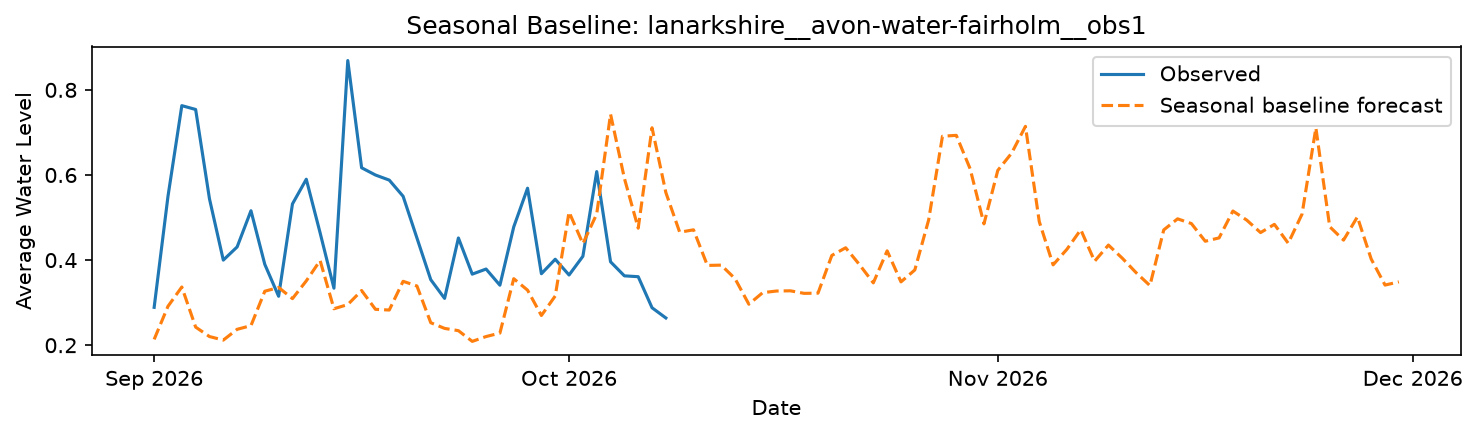

In [9]:
# Training data before September 2026
train_avg = filtered_avg.asfreq("D").loc[:"2026-08-31"]

# Forecast September-November 2026
forecast_dates = pd.date_range("2026-09-01", "2026-11-30")
baseline_forecast = pd.DataFrame(index=forecast_dates, columns=train_avg.columns, dtype=float)

# Equivalent dates from the previous six years
for date in forecast_dates:
    previous_dates = [date - pd.DateOffset(years=i) for i in range(1, 7)]
    baseline_forecast.loc[date] = train_avg.reindex(previous_dates).mean().values

# Evaluate predictions where observations are available
actual = filtered_avg.reindex(forecast_dates)
errors = actual - baseline_forecast

baseline_mae = errors.abs().stack().mean()
baseline_rmse = np.sqrt(errors.pow(2).stack().mean())

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Observations evaluated:", errors.notna().sum().sum())

# Plot predictions for a station
variation = baseline_forecast.std().dropna()
station = (variation - variation.median()).abs().idxmin()

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(actual.index, actual[station], label="Observed")
ax.plot(baseline_forecast.index, baseline_forecast[station], "--", label="Seasonal baseline forecast")
ax.set(xlabel="Date", ylabel="Average Water Level", title=f"Seasonal Baseline: {station}")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend()
plt.tight_layout()
plt.show()

*Figure 6: Baseline model accuracy for one station.*

Training observations: 496901
Observations evaluated: 12202


,Model,MAE,RMSE
0,Seasonal Baseline,0.1470,0.2230
1,Linear Regression,0.1418,0.2109


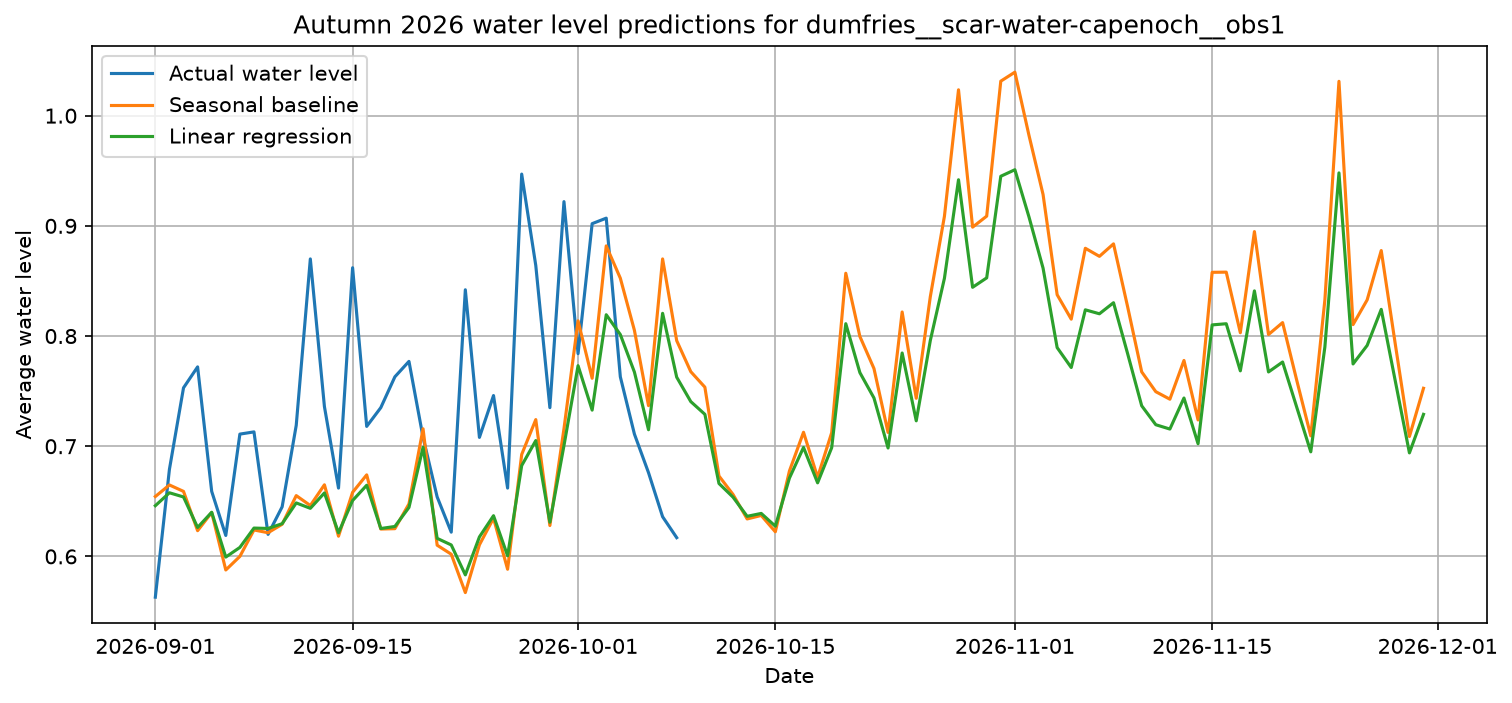

In [66]:

# Seasonal baseline model for autumn 2026
train_avg = filtered_avg.asfreq("D").loc[:"2026-08-31"]
forecast_dates = pd.date_range("2026-09-01", "2026-11-30")

baseline_forecast = pd.DataFrame(
    index=forecast_dates, columns=train_avg.columns, dtype=float
)

for date in forecast_dates:
    previous_dates = [date - pd.DateOffset(years=i) for i in range(1, 7)]
    baseline_forecast.loc[date] = train_avg.reindex(previous_dates).mean().values


# Use autumn 2020-2025 for training
train_dates = pd.date_range("2020-09-01", "2025-11-30")

# Calculate seasonal averages for training
historical_baseline = pd.DataFrame(
    index=train_dates, columns=train_avg.columns, dtype=float
)

for date in train_dates:
    previous_dates = [date - pd.DateOffset(years=i) for i in range(1, 7)]
    historical_baseline.loc[date] = train_avg.reindex(previous_dates).mean().values

# Calculate errors made by the seasonal baseline
historical_actual = train_avg.reindex(train_dates)
historical_errors = historical_actual - historical_baseline

# Prepare data for linear regression
train_data = historical_errors.stack().reset_index()
train_data.columns = ["Date", "Station", "Error"]

train_data["Seasonal_Average"] = [
    historical_baseline.loc[date, station]
    for date, station in zip(train_data["Date"], train_data["Station"])
]

# Add water level from the previous year
train_data["Previous_Year"] = [
    train_avg.loc[date - pd.DateOffset(years=1), station]
    for date, station in zip(train_data["Date"], train_data["Station"])
]

train_data = train_data.dropna()

# Define explanatory variables and target
X_train = train_data[["Seasonal_Average", "Previous_Year", "Station"]]
y_train = train_data["Error"]

# Scale numerical variables and encode station names
preprocessor = make_column_transformer(
    (StandardScaler(), ["Seasonal_Average", "Previous_Year"]),
    (OneHotEncoder(handle_unknown="ignore"), ["Station"])
)

# Fit linear regression model
pipe = make_pipeline(preprocessor, LinearRegression())
pipe.fit(X_train, y_train)


# Predict water levels for autumn 2026
forecast_data = baseline_forecast.stack().reset_index()
forecast_data.columns = ["Date", "Station", "Seasonal_Average"]

# Add water level from the previous year
forecast_data["Previous_Year"] = [
    train_avg.loc[date - pd.DateOffset(years=1), station]
    for date, station in zip(forecast_data["Date"], forecast_data["Station"])
]

# Replace missing previous year values with seasonal average
forecast_data["Previous_Year"] = forecast_data["Previous_Year"].fillna(
    forecast_data["Seasonal_Average"]
)

X_forecast = forecast_data[["Seasonal_Average", "Previous_Year", "Station"]]

# Predict corrections and add half to the seasonal baseline
forecast_data["Correction"] = pipe.predict(X_forecast)
forecast_data["Prediction"] = (
    forecast_data["Seasonal_Average"] + 0.5 * forecast_data["Correction"]
)

regression_2026 = forecast_data.pivot(
    index="Date", columns="Station", values="Prediction"
).reindex(index=forecast_dates, columns=train_avg.columns)


# Compare predictions with actual water levels
actual = filtered_avg.reindex(forecast_dates)

valid = (
    actual.notna()
    & baseline_forecast.notna()
    & regression_2026.notna()
)

comparison_2026 = pd.DataFrame({
    "Model": ["Seasonal Baseline", "Linear Regression"],
    "MAE": [
        (actual - p).where(valid).abs().stack().mean()
        for p in [baseline_forecast, regression_2026]
    ],
    "RMSE": [
        np.sqrt((actual - p).where(valid).pow(2).stack().mean())
        for p in [baseline_forecast, regression_2026]
    ]
})

print("Training observations:", len(X_train))
print("Observations evaluated:", valid.sum().sum())
display(comparison_2026.round(4))


# Plot actual and predicted water levels for one station
station = filtered_avg.columns[100]  

plt.figure(figsize=(12, 5))

plt.plot(actual.index, actual[station], label="Actual water level")
plt.plot(baseline_forecast.index, baseline_forecast[station], label="Seasonal baseline")
plt.plot(regression_2026.index, regression_2026[station], label="Linear regression")

plt.xlabel("Date")
plt.ylabel("Average water level")
plt.title(f"Autumn 2026 water level predictions for {station}")
plt.legend()
plt.grid(True)
plt.show()


# Model Fitting and Tuning

## Baseline Model

A seasonal baseline model was used to forecast daily average river water levels between September and November 2026. The approach was adapted from the equivalent-date forecasting method described in the Skforecast documentation $^2$.

For each forecasted date, the model calculated the mean water level recorded on the same day of the year over the previous six years, and used this to forecast the water level. This was performed independently for each monitoring station, producing forecasts for 91 days.

This method was selected because it provides a simple and interpretable baseline for evaluating more complex forecasting models. It allows predicted water levels to vary throughout the forecasting period according to historical seasonal behaviour, unlike a persistence model, which was also considered as a baseline. 

Model accuracy was assessed using mean absolute error (MAE) and root mean squared error (RMSE) for test dates where observations were available. Across 12,202 observations, the baseline had an MAE of 0.147 and an RMSE of 0.223. Figure 6 shows the seasonal baseline forecast for one monitoring station. The model captures variation in water level throughout the forecasting period, though differences are apparent, especially in September when water levels are underestimated. 

These results suggest that the seasonal baseline provides a reasonable benchmark for comparison with the final regression model, although it cannot account for sudden changes in water levels caused by unusual weather conditions.

# Interpretation, Discussion & Conclusions

The clustering analysis identified [XX] distinct groups of river monitoring stations across Scotland based on similarities in their water-level behaviour. The main distinguishing characteristics between these groups were [FEATURES].

The results of PCA suggested that two important aspects of river-level behaviour were the extent of general water-level variability and the magnitude and frequency of extreme fluctuations. The geographical distribution of the clusters also revealed [GEOGRAPHICAL FINDINGS].

One limitation of the analysis was the substantial proportion of missing observations in the original datasets. Although preprocessing reduced the percentage of missing observations from 30.61% to 1.33% in the average water-level dataset, approximately 25% of the original dates were removed. Consequently, the retained data may not be fully representative of river-level behaviour across the original time period.

Additionally, the engineered features were calculated across the retained time period, rather than accounting explicitly for seasonal variations in river-level behaviour. Monitoring stations exhibiting similar overall behaviour may behave differently at different times of the year.

The clustering results were also dependent on the choice of explanatory variables and clustering method. Further investigation into alternative feature sets and the stability of the resulting clusters could improve confidence in the findings.

This project investigated the application of supervised and unsupervised machine learning techniques to river-level monitoring data across Scotland.

The clustering analysis found that [MAIN CLUSTERING FINDINGS], whilst the supervised learning analysis demonstrated that [MAIN PREDICTION FINDINGS].

Together, these approaches demonstrate the potential for machine learning to improve understanding of river-level behaviour and support effective river management strategies across Scotland.

# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

$^1$ https://riverlevels.uk/map
$^2$ https://skforecast.org/latest/user_guides/forecasting-baseline.html
$^3$ https://riverlevels.uk/pages/frequently-asked-questions


In [36]:
!jupyter nbconvert --to pdf project.ipynb --template=latex --template-file=compact.tex.j2

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] Support files will be in project_files/
[NbConvertApp] Making directory ./project_files
[NbConvertApp] Writing 67590 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 583540 bytes to project.pdf
